# 02 · Model Training (Survival Analysis)

**Goal:** train survival models that predict *when* a fire reaches an evacuation zone, compare them with simpler approaches, and save the best.

- **Input:** `data/processed/train_clean.csv`
- **Output:** `models/fire_risk_model.joblib` and the test split `data/test/test_set.csv`

**Models**
- **Cox Proportional Hazards (Cox PH):** the classic survival model. Each feature raises or lowers the fire's "hazard" (its rate of hitting) by a fixed factor.
- **Random Survival Forest (RSF):** many survival trees averaged together. It can learn thresholds like "within 5 km".
- For comparison: **one classifier per time limit** (no time model) and a **baseline** that predicts the average.

From each survival curve S(t) we read **P(hit by t) = 1 − S(t)** at 12, 24, 48 and 72 h.

**Score (competition rule), higher is better:** **Hybrid = 0.3 × C-index + 0.7 × (1 − Brier)**
- **C-index:** are fires that hit sooner ranked as more urgent?
- **Brier:** are the percentages accurate? (lower is better)

In [1]:
# Libraries used in this notebook
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hide noisy warnings and find the project folders
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
# Tools for splitting, cross-validation and tuning, plus the models we compare
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest

# Project helpers: column names, the two model wrappers and the competition score
from src.data import feature_columns, TARGET_COLS, TIME_COL, EVENT_COL
from src.model import MultiHorizonModel, make_pipeline, SCORING
from src.survival import SurvivalModel

## 1. Split the data
85% for training, 15% kept aside for the final test in notebook 03.

In [2]:
# Load the cleaned data and group fires into censored / late hit / early hit
df = pd.read_csv(DATA_DIR / "processed" / "train_clean.csv")
FEATURES = feature_columns(df)
group = df[EVENT_COL] + ((df[EVENT_COL] == 1) & (df[TIME_COL] <= 12))

# Keep 15% of fires aside as the final test set (same mix of groups in both parts)
train, test = train_test_split(df, test_size=0.15, stratify=group, random_state=42)
(DATA_DIR / "test").mkdir(exist_ok=True)
test.to_csv(DATA_DIR / "test" / "test_set.csv", index=False)

# Inputs, answers (time + event, so censoring is kept), and the 5 cross-validation folds
X, y = train[FEATURES], train[TARGET_COLS].to_numpy()
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X, group.loc[train.index]))
print("Train:", len(train), "fires | Test:", len(test), "fires")

Train: 187 fires | Test: 34 fires


## 2. Compare models
Every model uses the same pipeline: **add features → fill missing values and scale → model**.
The survival models are trained once on (time, event) for all fires; the classifier approach trains a separate model for each time limit.

In [3]:
# The models to compare: two survival models (core) and two reference approaches
models = {
    "Baseline (average)": MultiHorizonModel(make_pipeline(DummyClassifier(strategy="prior"))),
    "Classifier per time limit (RF)": MultiHorizonModel(make_pipeline(RandomForestClassifier(n_estimators=300, random_state=42))),
    "Cox PH": SurvivalModel(make_pipeline(CoxPHSurvivalAnalysis(alpha=1.0))),
    "Random Survival Forest": SurvivalModel(make_pipeline(RandomSurvivalForest(n_estimators=300, min_samples_leaf=5, random_state=42))),
}
SURVIVAL = {"Cox PH", "Random Survival Forest"}

# Score each model with 5-fold cross-validation (Hybrid, C-index and Brier)
rows = []
for name, model in models.items():
    r = cross_validate(model, X, y, cv=folds, scoring=SCORING, n_jobs=-1)
    rows.append({"model": name, "type": "survival" if name in SURVIVAL else "classification",
                 "hybrid": r["test_hybrid"].mean(), "c_index": r["test_c_index"].mean(), "brier": -r["test_neg_brier"].mean()})
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,type,hybrid,c_index,brier
model,,,,
Baseline (average),classification,0.7381,0.5000,0.1599
Classifier per time limit (RF),classification,0.9725,0.9452,0.0158
Cox PH,survival,0.9278,0.9091,0.0642
Random Survival Forest,survival,0.9696,0.9486,0.0215


## 3. Tune the models
Try a few settings for each model and keep the best by Hybrid score. The classifier is tuned too, so the comparison is fair.

In [4]:
# Settings to try for each model
grids = {
    "Cox PH": {"estimator__clf__alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Survival Forest": {"estimator__clf__min_samples_leaf": [3, 5, 10, 15], "estimator__clf__max_features": ["sqrt", 0.5, None]},
    "Classifier per time limit (RF)": {"estimator__clf__min_samples_leaf": [1, 3, 5, 10], "estimator__clf__max_features": ["sqrt", 0.5]},
}
# Run the search for each model and record the best score
searches = {}
for name, grid in grids.items():
    searches[name] = GridSearchCV(models[name], grid, cv=folds, scoring=SCORING, refit="hybrid", n_jobs=-1).fit(X, y)
    best = pd.DataFrame(searches[name].cv_results_).loc[searches[name].best_index_]
    results.loc[name + " (tuned)"] = ["survival" if name in SURVIVAL else "classification",
                                      best["mean_test_hybrid"], best["mean_test_c_index"], -best["mean_test_neg_brier"]]
    print(f"{name}: best settings {searches[name].best_params_}")
results.sort_values("hybrid", ascending=False).round(4)

Cox PH: best settings {'estimator__clf__alpha': 10}


Random Survival Forest: best settings {'estimator__clf__max_features': 0.5, 'estimator__clf__min_samples_leaf': 3}


Classifier per time limit (RF): best settings {'estimator__clf__max_features': 0.5, 'estimator__clf__min_samples_leaf': 5}


,type,hybrid,c_index,brier
model,,,,
Random Survival Forest (tuned),survival,0.9777,0.9558,0.0129
Classifier per time limit (RF) (tuned),classification,0.9760,0.9538,0.0144
Classifier per time limit (RF),classification,0.9725,0.9452,0.0158
Random Survival Forest,survival,0.9696,0.9486,0.0215
Cox PH (tuned),survival,0.9352,0.9135,0.0554
Cox PH,survival,0.9278,0.9091,0.0642
Baseline (average),classification,0.7381,0.5000,0.1599


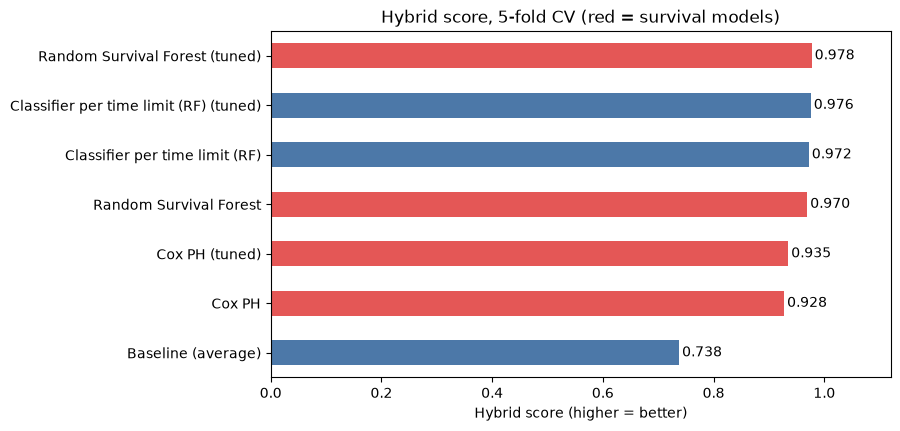

In [5]:
# Bar chart of every model's Hybrid score (red = survival models)
plot = results.sort_values("hybrid")
plot["hybrid"].plot.barh(color=["#E45756" if t == "survival" else "#4C78A8" for t in plot["type"]], figsize=(8, 4.5))
for i, v in enumerate(plot["hybrid"]): plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1.12); plt.title("Hybrid score, 5-fold CV (red = survival models)"); plt.xlabel("Hybrid score (higher = better)"); plt.ylabel("")
plt.savefig(FIG_DIR / "02_model_comparison.png", bbox_inches="tight"); plt.show()

## 4. Save the best survival model
The final model is the survival model with the highest Hybrid score.

In [6]:
# Pick the best survival model and save it with its feature list and the comparison table
surv = results[results["type"] == "survival"].sort_values("hybrid", ascending=False)
final_name = surv.index[0]
final_model = searches[final_name.replace(" (tuned)", "")].best_estimator_ if final_name.endswith("(tuned)") else models[final_name].fit(X, y)
table = results.reset_index().assign(final=lambda d: d["model"] == final_name).round(4).to_dict("records")

(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "features": FEATURES, "model_name": final_name,
             "cv_hybrid": float(results.loc[final_name, "hybrid"]), "cv_table": table},
            ROOT / "models" / "fire_risk_model.joblib")
print("Final model:", final_name, "| CV Hybrid: %.3f" % results.loc[final_name, "hybrid"])

Final model: Random Survival Forest (tuned) | CV Hybrid: 0.978


## Summary
- **The Random Survival Forest is the best model.** It models the full time-to-hit curve and uses censored fires properly, and it scores higher than predicting each time limit separately.
- **Cox PH scores lower.** It assumes each feature has a fixed, smooth effect, which cannot capture the sharp "within 5 km" rule in this data.
- **Both survival models predict *when*** a fire will hit, not only *whether* (see notebook 03).